# 16 · 深入推荐：负例、序列与索引
先预测：难负例一定更好？顺序模型一定胜过均值？索引更快是否意味着推荐更准？

本章复用原Retailrocket时间切分、因果样本、全库验证指标及工作台。只读取最新**完成**的推荐实验，不自动重训。训练命令：`python -m reclab.deep_recommendation`。训练预算12000样本×4轮×2种子；未训练至收敛，不代表结构上限。没有使用保留测试窗口。

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT/'reclab').is_dir(): ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from reclab.experiments import catalog, result
runs=[r for r in catalog() if r['domain']=='recommendation' and r['state']=='completed' and not r.get('annotation',{}).get('superseded')]
assert runs, '先运行 python -m reclab.deep_recommendation'
receipt=runs[-1]; experiment=result('recommendation',receipt['run_id'])
print(receipt['run_id'], 'samples',experiment['samples'], 'users',experiment['evaluation_users'])
print(experiment['scope'])
frame=pd.DataFrame([{k:v for k,v in row.items() if k not in ('loss','index','shuffled')} for row in experiment['rows']])
display(frame[['encoder','sampler','seed','parameters','ndcg@20','recall@20','coverage@20']])

20261030T123443-578def14 samples 12000 users 339
Bounded real-data ablation; loss is not CTR; popularity proposal uses train-only aggregate frequency; hard negatives are model-selected from 16 unseen-prefix candidates. Validation is a visible development benchmark, not an untouched audit.


,encoder,sampler,seed,parameters,ndcg@20,recall@20,coverage@20
0,mean,uniform,42,120624,0.007160,0.007526,0.3510
1,mean,popular,42,120624,0.003932,0.005230,0.4450
2,mean,hard,42,120624,0.005239,0.008450,0.2938
3,gru,uniform,42,124224,0.002641,0.003189,0.2300
4,attention,uniform,42,123504,0.004672,0.007186,0.1514
5,mean,uniform,2026,120624,0.001771,0.002463,0.3554
6,mean,popular,2026,120624,0.002815,0.005158,0.4232
7,mean,hard,2026,120624,0.001483,0.002045,0.2626
8,gru,uniform,2026,124224,0.002450,0.002017,0.2586
9,attention,uniform,2026,123504,0.003738,0.002698,0.1406


## 1 · 负采样：先只改提议分布
同一个mean编码器，比较均匀、训练频率^.75、16候选中取模型最高分的hard负例。屏蔽当前正例和因果前缀；未知的未来正例可能成为假负例。所有臂使用相同样本、批次顺序、初始化种子和优化预算。不同负例分布的loss不可直接比较。

ndcg@20           recall@20           coverage@20          
             mean       std      mean       std        mean       std
sampler                                                              
hard     0.003361  0.002656  0.005247  0.004528      0.2782  0.022062
popular  0.003374  0.000790  0.005194  0.000051      0.4341  0.015415
uniform  0.004466  0.003811  0.004994  0.003580      0.3532  0.003111

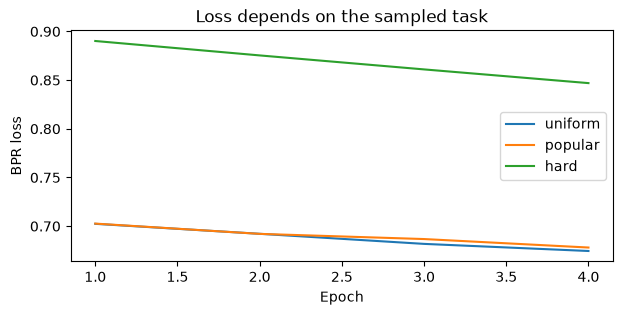

In [2]:
means=frame[frame.encoder=='mean'].groupby('sampler')[['ndcg@20','recall@20','coverage@20']].agg(['mean','std'])
display(means)
fig,ax=plt.subplots(figsize=(7,3))
for row in experiment['rows']:
    if row['encoder']=='mean' and row['seed']==42: ax.plot(range(1,len(row['loss'])+1),row['loss'],label=row['sampler'])
ax.set(xlabel='Epoch',ylabel='BPR loss',title='Loss depends on the sampled task');ax.legend();plt.show()

## 2 · 序列：参数量与顺序都要看
比较mean、GRU、带位置编码的自注意力池化；这是教学序列编码器，不是SASRec或DIN完整论文复现。GRU对左padding做pack处理，注意力屏蔽padding。模型没有用户ID特征。

同一模型再打乱历史做推理消融；这衡量对顺序的敏感性，不证明顺序带来因果收益。两个种子也不足以声称统计显著。

,ndcg@20,recall@20,parameters
encoder,,,
attention,0.004205,0.004942,123504.0
gru,0.002546,0.002603,124224.0
mean,0.004466,0.004994,120624.0


,encoder,seed,original,shuffled
0,mean,42,0.007160,0.007160
1,gru,42,0.002641,0.006853
2,attention,42,0.004672,0.003519
3,mean,2026,0.001771,0.001771
4,gru,2026,0.002450,0.002790
5,attention,2026,0.003738,0.003169


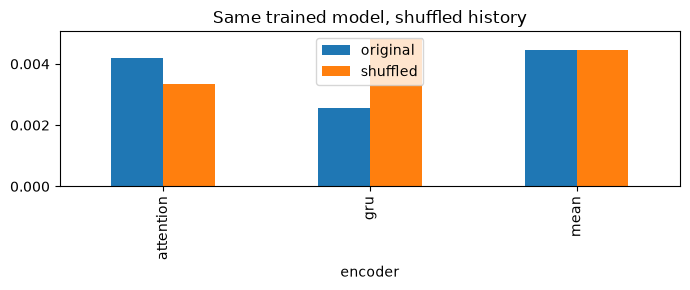

In [3]:
uniform=frame[frame.sampler=='uniform']
display(uniform.groupby('encoder')[['ndcg@20','recall@20','parameters']].mean())
shuffle=pd.DataFrame([{'encoder':r['encoder'],'seed':r['seed'],'original':r['ndcg@20'],'shuffled':r['shuffled']['ndcg@20']} for r in experiment['rows'] if r['sampler']=='uniform'])
display(shuffle)
shuffle.groupby('encoder')[['original','shuffled']].mean().plot.bar(figsize=(7,3),title='Same trained model, shuffled history');plt.tight_layout();plt.show()

## 3 · 索引：分开看模型召回和检索近似
复用课程中的12簇粗索引，probes=1/4/12。记录扫描量、对精确Top20的重合率、真实标签Recall/NDCG。扫描12簇应退化到精确检索；小词表上不预设近似方法更快。

,seed,probes,exact_top20_overlap,mean_scanned,seconds,recall@20,ndcg@20,mrr@20,hit_rate@20
0,42,1,0.287463,421.404130,0.034856,0.002371,0.002808,0.005616,0.026549
1,42,4,0.708997,1673.713864,0.079289,0.006380,0.007160,0.012372,0.032448
2,42,12,1.000000,5000.000000,0.185076,0.007526,0.007160,0.010735,0.035398
3,2026,1,0.301622,407.519174,0.034720,0.002246,0.002125,0.004994,0.026549
4,2026,4,0.743215,1643.324484,0.078714,0.001008,0.001674,0.005415,0.020649
5,2026,12,1.000000,5000.000000,0.194151,0.002463,0.001771,0.003196,0.020649


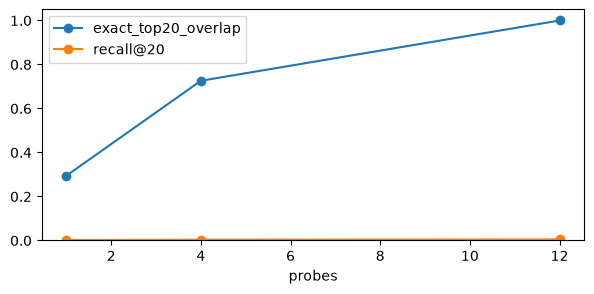

In [4]:
index=pd.DataFrame([{'seed':r['seed'],**i} for r in experiment['rows'] for i in r.get('index',[])])
assert (index[index.probes==12].exact_top20_overlap==1).all()
display(index)
index.groupby('probes')[['exact_top20_overlap','recall@20']].mean().plot(marker='o',figsize=(7,3));plt.ylim(0,1.05);plt.show()

## 4 · 你来改一个变量
先记录预测，再改变`Config`中的history、dim、epochs或samples之一，运行新实验，再重跑本章。实验会新建目录，旧权重不覆盖。比较结果要同时看预算、参数量、热门偏置与覆盖率；正式旧双塔和竞赛流程保持独立可用。

In [5]:
from reclab.deep_recommendation import Config, SequenceEncoder, negatives
import inspect
print(inspect.getsource(negatives))
assert len(experiment['rows'])==len(receipt['config']['seeds'])*5
assert all(len(r['loss'])==receipt['config']['epochs'] for r in experiment['rows'])
print('PASS: complete controls and index parity checked')

def negatives(history, positives, probability, rng, width=1):
    # Only causal prefix and current target are excluded. Unknown future positives remain unknown.
    out = rng.choice(len(probability), size=(len(history), width), p=probability)
    blocked = [set(row) | {int(pos), 0} for row, pos in zip(history, positives)]
    if any(sum(probability[i] for i in b) >= 1 - 1e-12 for b in blocked):
        raise ValueError('No negative support')
    for row, excluded in enumerate(blocked):
        for _ in range(100):
            bad = np.isin(out[row], list(excluded))
            if not bad.any():
                break
            out[row, bad] = rng.choice(len(probability), size=int(bad.sum()), p=probability)
        else:
            raise RuntimeError('Negative sampling failed')
    return out

PASS: complete controls and index parity checked
